# US State Economic Factors (2014–2025)

This notebook integrates economic indicators from the Bureau of Economic Analysis (BEA) and Bureau of Labor Statistics (BLS) into a unified state–year dataset for subsequent analysis of documented cybersecurity incidents.

## 1. Objective and data sources

**Unit of observation:** One US state in one year.

**Coverage:** 50 US states, 2014–2025 (600 observations).


**Data sources and preprocessing notebooks:**

- **BEA:** GDP, personal income, population, and economic growth - [01_bea.ipynb](01_bea.ipynb)
- **BLS LAUS:** Employment, unemployment, and labor force participation - [02_bls_laus.ipynb](02_bls_laus.ipynb)
- **BLS QCEW:** Business establishments, covered employment, and wages - [03_bls_qcew.ipynb](03_bls_qcew.ipynb)

Only previously cleaned datasets are used. Industry-level BEA and QCEW data are retained separately to preserve their original level of observation.



In [1]:

from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt


In [2]:

# Locate processed economic datasets
PROJECT_ROOT = Path.cwd().resolve().parents[1]
DATA_DIR = PROJECT_ROOT / "data" / "processed" / "economic"

files = {
    "BEA": DATA_DIR / "bea" / "bea_state_economic_2014_2025.csv",
    "LAUS": DATA_DIR / "bls_laus" / "laus_state_2014_2025.csv",
    "QCEW": DATA_DIR / "bls_qcew" / "qcew_state_2014_2025.csv",
}

datasets = {
    name: pd.read_csv(path, dtype={"state_fips": str})
    for name, path in files.items()
}

overview = pd.DataFrame([
    {
        "source": name,
        "rows": len(df),
        "states": df["state_fips"].nunique(),
        "years": df["year"].nunique(),
        "columns": len(df.columns)
    }
    for name, df in datasets.items()
])

display(overview)


,source,rows,states,years,columns
0,BEA,600,50,12,10
1,LAUS,600,50,12,10
2,QCEW,600,50,12,8


## 2. Data integration

The three datasets are merged using `state_fips` and `year` as common identifiers.

Overlapping variable names are standardized to distinguish labor market estimates (LAUS) from workplace-based employment measures (QCEW). The BEA dataset provides the reference state names.

A one-to-one merge is required to preserve exactly one observation per state and year.


In [3]:
# Prepare source-specific variable names
bea = datasets["BEA"].copy()

laus = datasets["LAUS"].drop(columns="state").rename(columns={
    "civilian_population": "laus_civilian_population",
    "employment": "laus_employment",
    "unemployment": "laus_unemployment",
    "labor_force": "laus_labor_force"
})

qcew = datasets["QCEW"].drop(columns="state").rename(columns={
    "establishments": "qcew_establishments",
    "employment": "qcew_employment",
    "total_annual_wages": "qcew_total_annual_wages",
    "avg_annual_pay": "qcew_avg_annual_pay",
    "employees_per_establishment": "qcew_employees_per_establishment"
})

keys = ["state_fips", "year"]

# Confirm each source has unique state-year records
for name, df in [("BEA", bea), ("LAUS", laus), ("QCEW", qcew)]:
    assert not df.duplicated(keys).any(), f"Duplicate records in {name}"

# Merge economic indicators
economic_factors = (
    bea
    .merge(laus, on=keys, how="left", validate="one_to_one")
    .merge(qcew, on=keys, how="left", validate="one_to_one")
    .sort_values(keys)
    .reset_index(drop=True)
)

print("Observations:", len(economic_factors))
print("Columns:", len(economic_factors.columns))

display(economic_factors.head())


Observations: 600
Columns: 22


,state_fips,state,year,gdp_nominal,gdp_real,personal_income,population,personal_income_per_capita,gdp_per_capita,real_gdp_growth_pct,...,labor_force_participation_rate,laus_employment,employment_population_ratio,laus_unemployment,unemployment_rate,qcew_establishments,qcew_employment,qcew_total_annual_wages,qcew_avg_annual_pay,qcew_employees_per_establishment
0,01,Alabama,2014,1.970644e+11,2.060700e+11,1.794295e+11,4887757.0,36710.0,40317.961797,-0.431430,...,56.9,2022380.0,53.1,146711.0,6.8,117452,1863561,80668352987,43287,15.866575
1,01,Alabama,2015,2.031133e+11,2.089503e+11,1.874171e+11,4909177.0,38177.0,41374.205901,1.397729,...,56.7,2040087.0,53.2,132532.0,6.1,119251,1890340,83690526044,44273,15.851775
2,01,Alabama,2016,2.088243e+11,2.128628e+11,1.908120e+11,4931579.0,38692.0,42344.307979,1.872455,...,57.0,2069474.0,53.7,127022.0,5.8,122310,1915306,85866639650,44832,15.659439
3,01,Alabama,2017,2.166155e+11,2.166155e+11,1.979006e+11,4953096.0,39955.0,43733.353846,1.762967,...,56.9,2107659.0,54.3,99608.0,4.5,124881,1936819,89088710816,45997,15.509317
4,01,Alabama,2018,2.262638e+11,2.207846e+11,2.056250e+11,4977088.0,41314.0,45461.080857,1.924655,...,57.3,2148823.0,55.1,87338.0,3.9,127260,1961625,93007888078,47414,15.414309



## 3. Data quality and validation

The integrated dataset is checked for complete state–year coverage, duplicate records, missing values, and consistency of geographic identifiers.

No missing values are imputed. The original source measurements are preserved.


In [4]:
keys = ["state_fips", "year"]

# Validate geographic and temporal coverage
assert len(economic_factors) == 600
assert economic_factors["state_fips"].nunique() == 50
assert set(economic_factors["year"]) == set(range(2014, 2026))
assert not economic_factors.duplicated(keys).any()

# Confirm every source has exactly the same state-year combinations
reference_keys = pd.MultiIndex.from_frame(bea[keys])

for name, df in [("LAUS", laus), ("QCEW", qcew)]:
    source_keys = pd.MultiIndex.from_frame(df[keys])
    assert reference_keys.difference(source_keys).empty, f"Missing {name} records"
    assert source_keys.difference(reference_keys).empty, f"Extra {name} records"

# Summarize missing values
missing_summary = (
    economic_factors.isna()
    .sum()
    .rename("missing_values")
    .to_frame()
)

missing_summary["missing_pct"] = (
    100 * missing_summary["missing_values"] / len(economic_factors)
)

display(missing_summary[missing_summary["missing_values"] > 0])


,missing_values,missing_pct



## 4. Economic indicators and EDA

Establishment density is additionally calculated to support comparisons between states of different population sizes.



In [5]:
# Calculate business establishments per 10,000 residents
economic_factors["establishments_per_10k"] = (
    economic_factors["qcew_establishments"]
    / economic_factors["population"] * 10_000
)

assert economic_factors["establishments_per_10k"].notna().all()
assert (economic_factors["establishments_per_10k"] > 0).all()

display(
    economic_factors[
        ["state", "year", "gdp_per_capita", "establishments_per_10k"]
    ].head()
)


,state,year,gdp_per_capita,establishments_per_10k
0,Alabama,2014,40317.961797,240.298362
1,Alabama,2015,41374.205901,242.914444
2,Alabama,2016,42344.307979,248.013871
3,Alabama,2017,43733.353846,252.127154
4,Alabama,2018,45461.080857,255.691682



### 4.1. GDP per capita and establishment density

The relationship between GDP per capita and business establishment density is examined across the 50 US states in 2025.

The scatter plot provides an initial descriptive comparison of economic development and business activity. It does not establish a causal relationship.


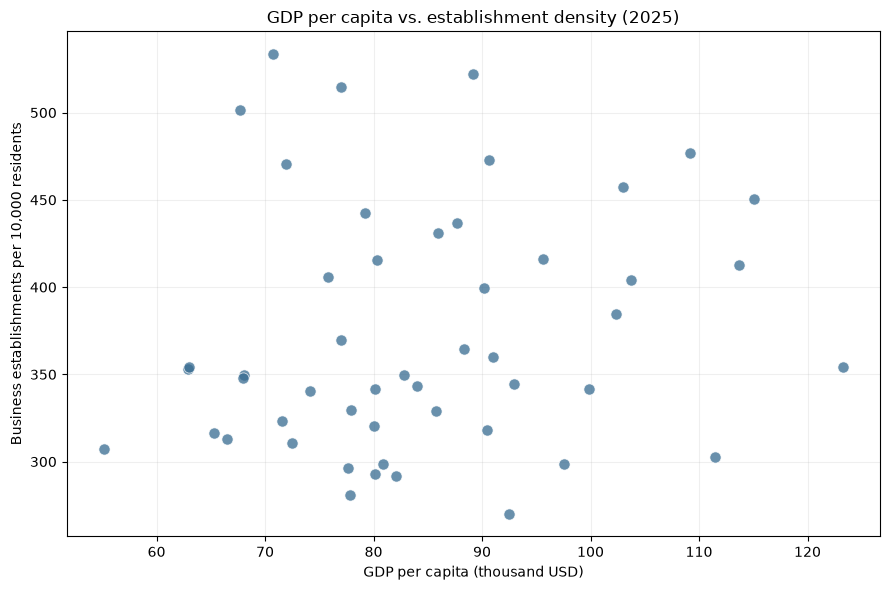

In [13]:
# Compare GDP per capita and establishment density in 2025
data_2025 = economic_factors.loc[economic_factors["year"] == 2025]

fig, ax = plt.subplots(figsize=(9, 6))

ax.scatter(
    data_2025["gdp_per_capita"] / 1_000,
    data_2025["establishments_per_10k"],
    alpha=0.75,
    s=65,
    color="#376B91",
    edgecolor="white",
    linewidth=0.6
)

ax.set(
    title="GDP per capita vs. establishment density (2025)",
    xlabel="GDP per capita (thousand USD)",
    ylabel="Business establishments per 10,000 residents"
)

ax.grid(alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()


### 4.2. Correlations between economic indicators

Pearson correlations are calculated across the 50 US states in 2025 to examine relationships between economic development, labor market conditions, and business activity.

The correlation matrix helps identify indicators that convey similar information and potential multicollinearity in subsequent statistical models. Correlations are descriptive and do not imply causation.


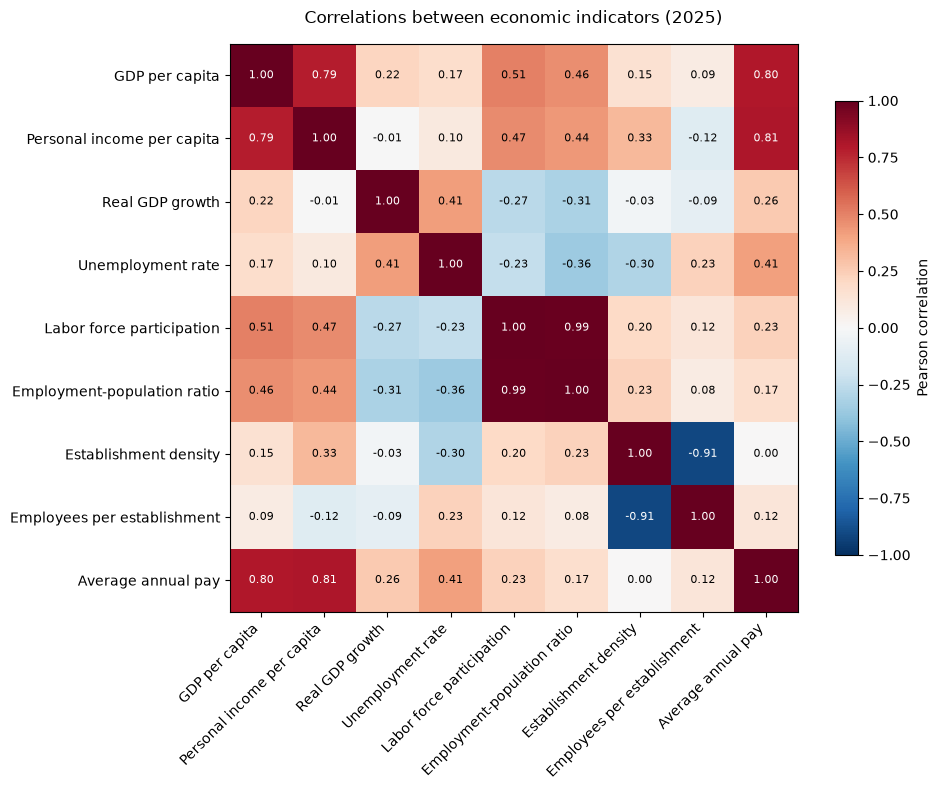

In [16]:

# Select economic indicators for the 2025 cross-sectional analysis
indicators = {
    "gdp_per_capita": "GDP per capita",
    "personal_income_per_capita": "Personal income per capita",
    "real_gdp_growth_pct": "Real GDP growth",
    "unemployment_rate": "Unemployment rate",
    "labor_force_participation_rate": "Labor force participation",
    "employment_population_ratio": "Employment-population ratio",
    "establishments_per_10k": "Establishment density",
    "qcew_employees_per_establishment": "Employees per establishment",
    "qcew_avg_annual_pay": "Average annual pay"
}

data_2025 = economic_factors.loc[
    economic_factors["year"] == 2025, list(indicators)
].rename(columns=indicators)

correlations = data_2025.corr(method="pearson")

fig, ax = plt.subplots(figsize=(10, 8))

im = ax.imshow(correlations, cmap="RdBu_r", vmin=-1, vmax=1)

ax.set_xticks(range(len(indicators)), labels=correlations.columns,
              rotation=45, ha="right")
ax.set_yticks(range(len(indicators)), labels=correlations.index)

for i in range(len(indicators)):
    for j in range(len(indicators)):
        value = correlations.iloc[i, j]
        ax.text(
            j, i, f"{value:.2f}",
            ha="center", va="center", fontsize=8,
            color="white" if abs(value) > 0.65 else "black"
        )

fig.colorbar(im, ax=ax, label="Pearson correlation", shrink=0.8)
ax.set_title("Correlations between economic indicators (2025)", pad=15)

plt.tight_layout()

FIGURES_DIR = PROJECT_ROOT / "figures" / "economic" / "combined" / "static"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

fig.savefig(
    FIGURES_DIR / "04_01_economic_correlations_2025.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()



The correlation matrix reveals several strong relationships among economic indicators in 2025.

Labor force participation and the employment-population ratio are nearly perfectly correlated (r = 0.99), indicating substantial redundancy. GDP per capita, personal income per capita, and average annual pay are also strongly positively correlated (r = 0.79–0.81).

Establishment density and employees per establishment show a strong negative correlation (r = −0.91), partly reflecting their shared mathematical components.

**In contrast, GDP per capita and establishment density are weakly correlated (r = 0.15), suggesting that these indicators capture different aspects of state economic structure.**

These findings will inform variable selection in subsequent analyses of documented cybersecurity incidents.



## 5. Export and conclusions

The integration produces a complete panel of 50 US states over 12 years (2014–2025), combining economic output, income, population, labor market conditions, and business activity.

The 2025 correlation analysis reveals substantial overlap among several indicators, particularly labor force participation and the employment-population ratio. In contrast, GDP per capita and establishment density show only a weak correlation.

These findings will inform the selection of economic variables for subsequent analysis of documented cybersecurity incidents. The relationships are descriptive and do not establish causality.

The validated dataset is exported for use in `05_incidents_economic_eda.ipynb`.


In [17]:
# Final validation
assert economic_factors.shape == (600, 23)
assert not economic_factors.duplicated(["state_fips", "year"]).any()
assert economic_factors.notna().all().all()

# Export the integrated economic dataset
OUTPUT_DIR = PROJECT_ROOT / "data" / "processed" / "economic" / "combined"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

output_file = OUTPUT_DIR / "usa_state_economic_factors_2014_2025.csv"

economic_factors.to_csv(output_file, index=False)

print(f"Exported: {output_file.relative_to(PROJECT_ROOT)}")
print(f"Shape: {economic_factors.shape}")
print(f"Missing values: {economic_factors.isna().sum().sum()}")


Exported: data\processed\economic\combined\usa_state_economic_factors_2014_2025.csv
Shape: (600, 23)
Missing values: 0
